# simulating start time

In [131]:
import numpy.random
import numpy as np
t_rxn = 100
t_osc = 1

N = 100000
t_wait = np.random.exponential(t_rxn, N)
for i in range(N):
    t_wait[N-i-1] += np.sum(t_wait[:N-i-1]) 
    t_wait[N-i-1] = t_wait[N-i-1] % t_osc



(array([20176., 19879., 19964., 19948., 20033.]),
 array([8.00006092e-06, 2.00005214e-01, 4.00002428e-01, 5.99999642e-01,
        7.99996856e-01, 9.99994070e-01]),
 <BarContainer object of 5 artists>)

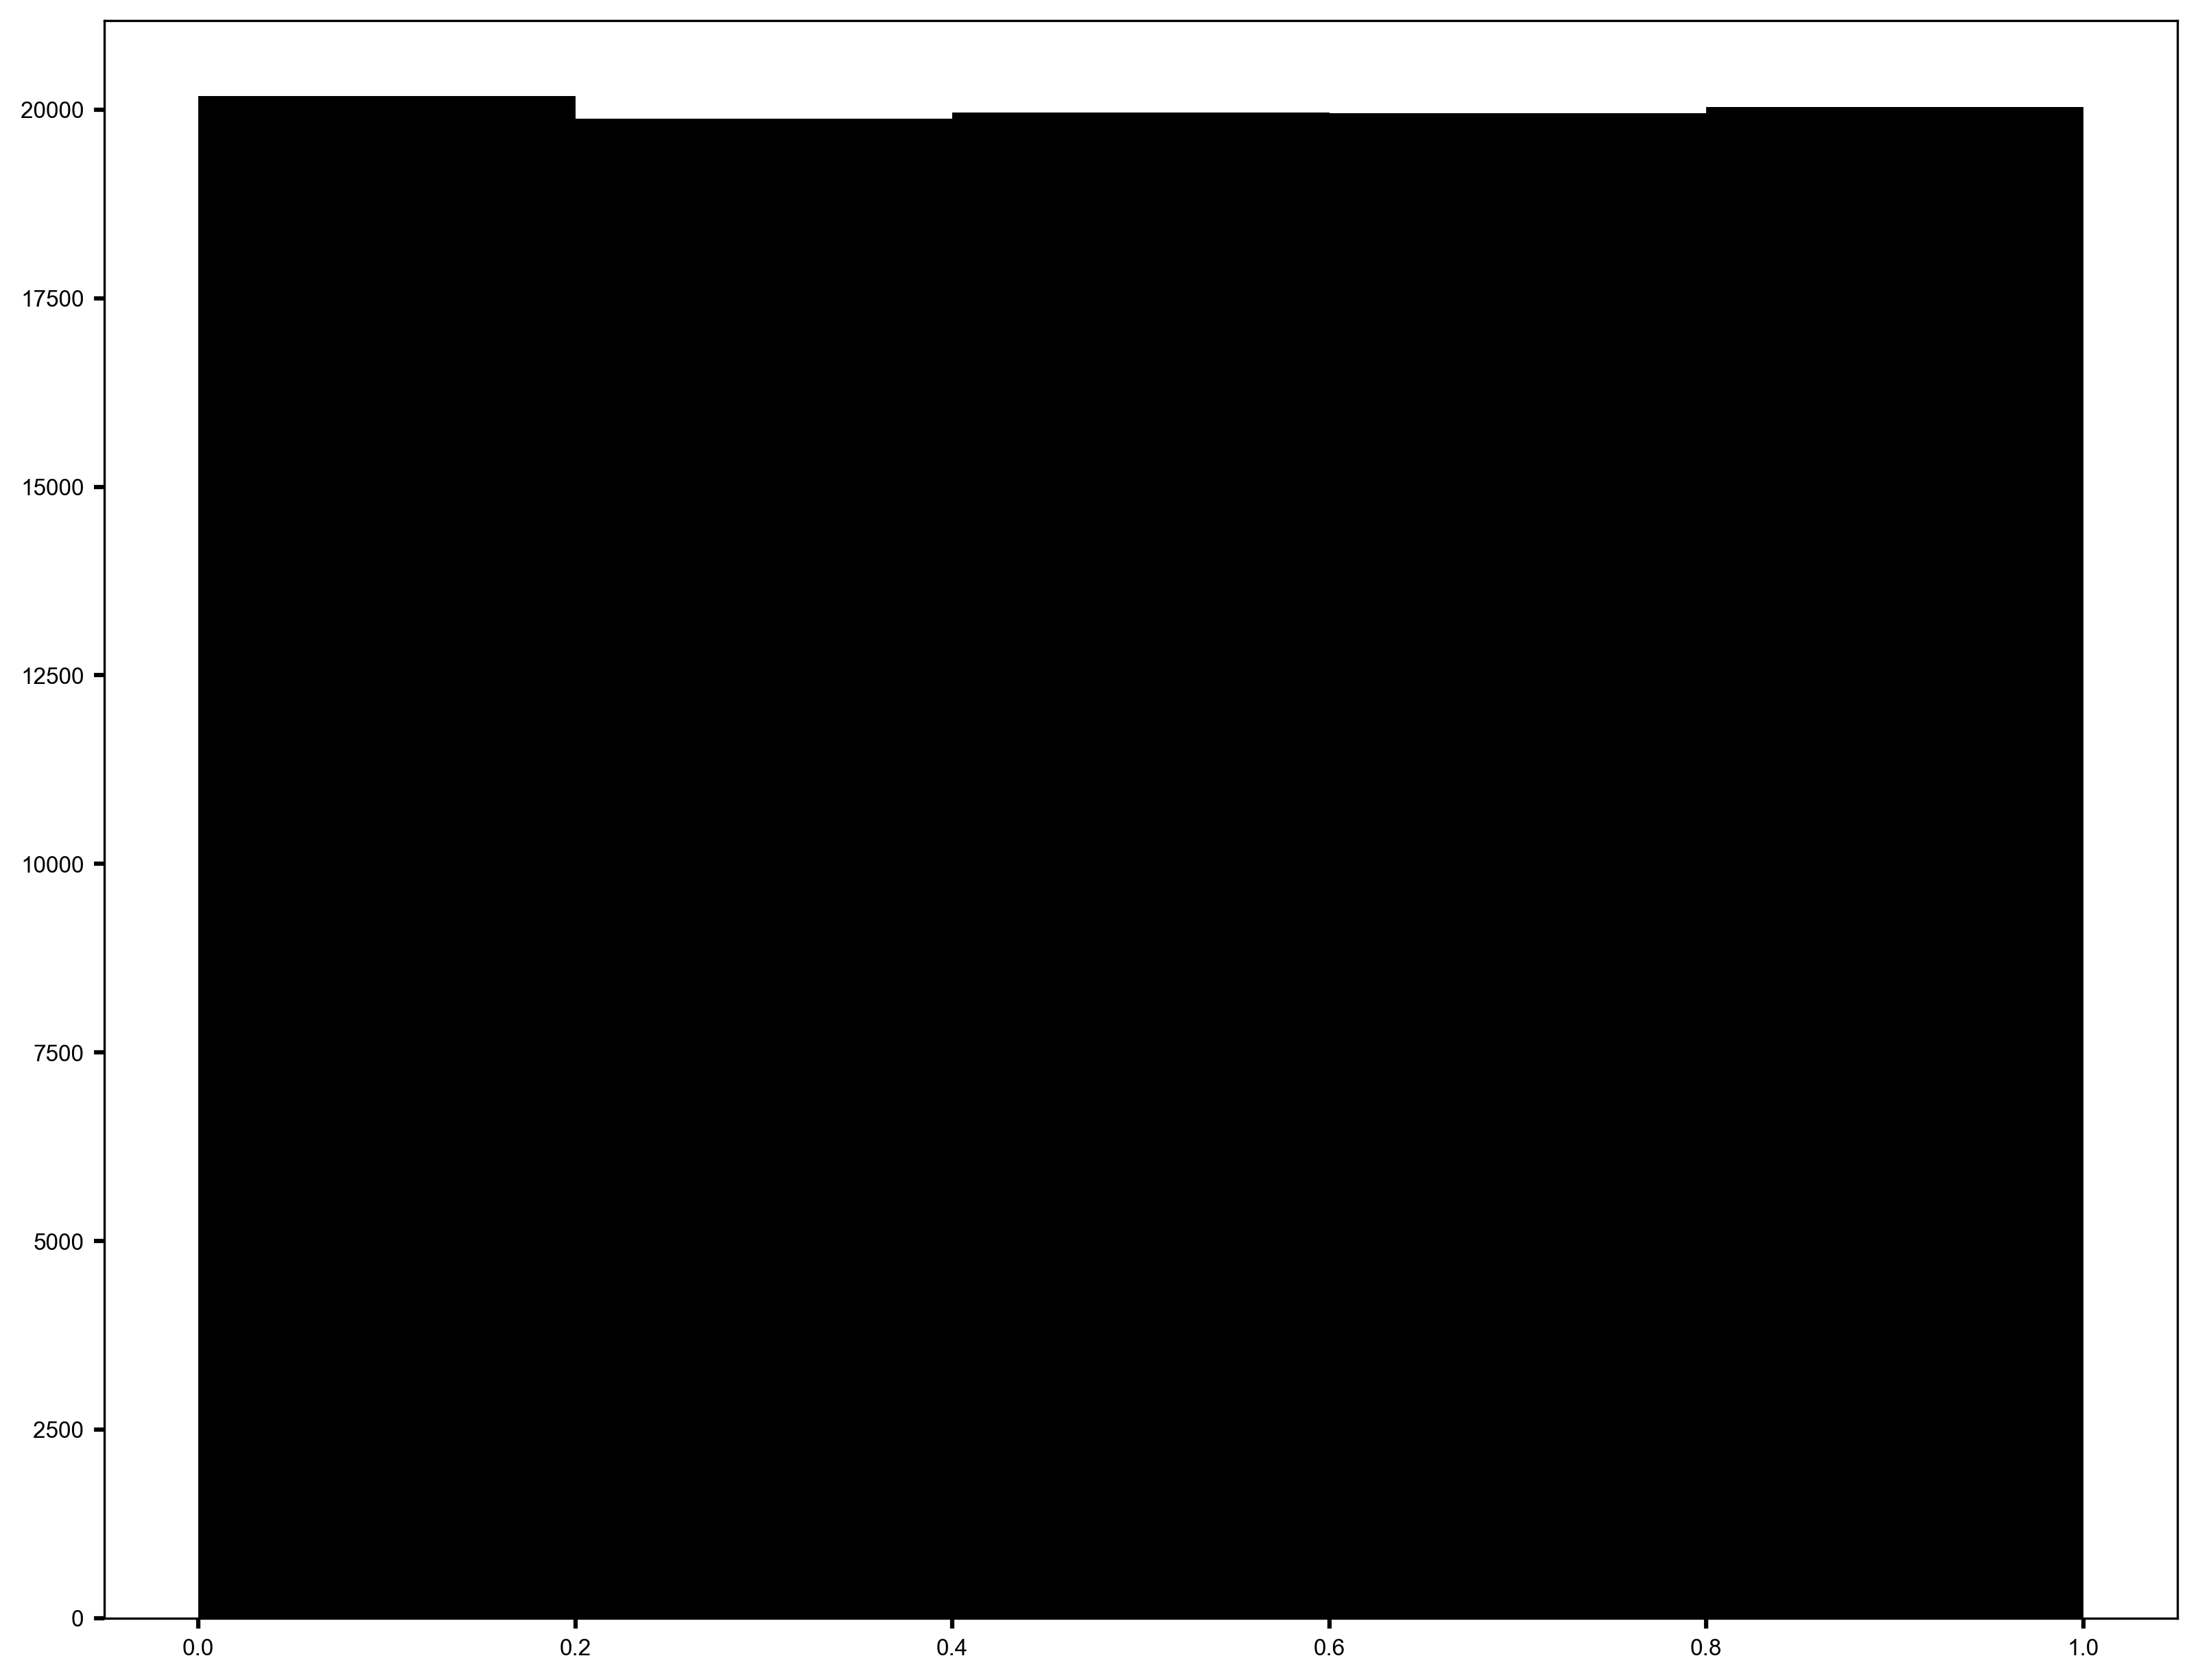

In [132]:
import matplotlib.pyplot as plt
    
plt.hist(t_wait, bins=5)

(array([5.866e+03, 2.402e+03, 1.015e+03, 4.190e+02, 1.790e+02, 7.500e+01,
        2.700e+01, 1.000e+01, 5.000e+00, 2.000e+00]),
 array([1.54880050e-04, 8.82861368e+00, 1.76570725e+01, 2.64855313e+01,
        3.53139901e+01, 4.41424489e+01, 5.29709077e+01, 6.17993665e+01,
        7.06278253e+01, 7.94562841e+01, 8.82847429e+01]),
 <BarContainer object of 10 artists>)

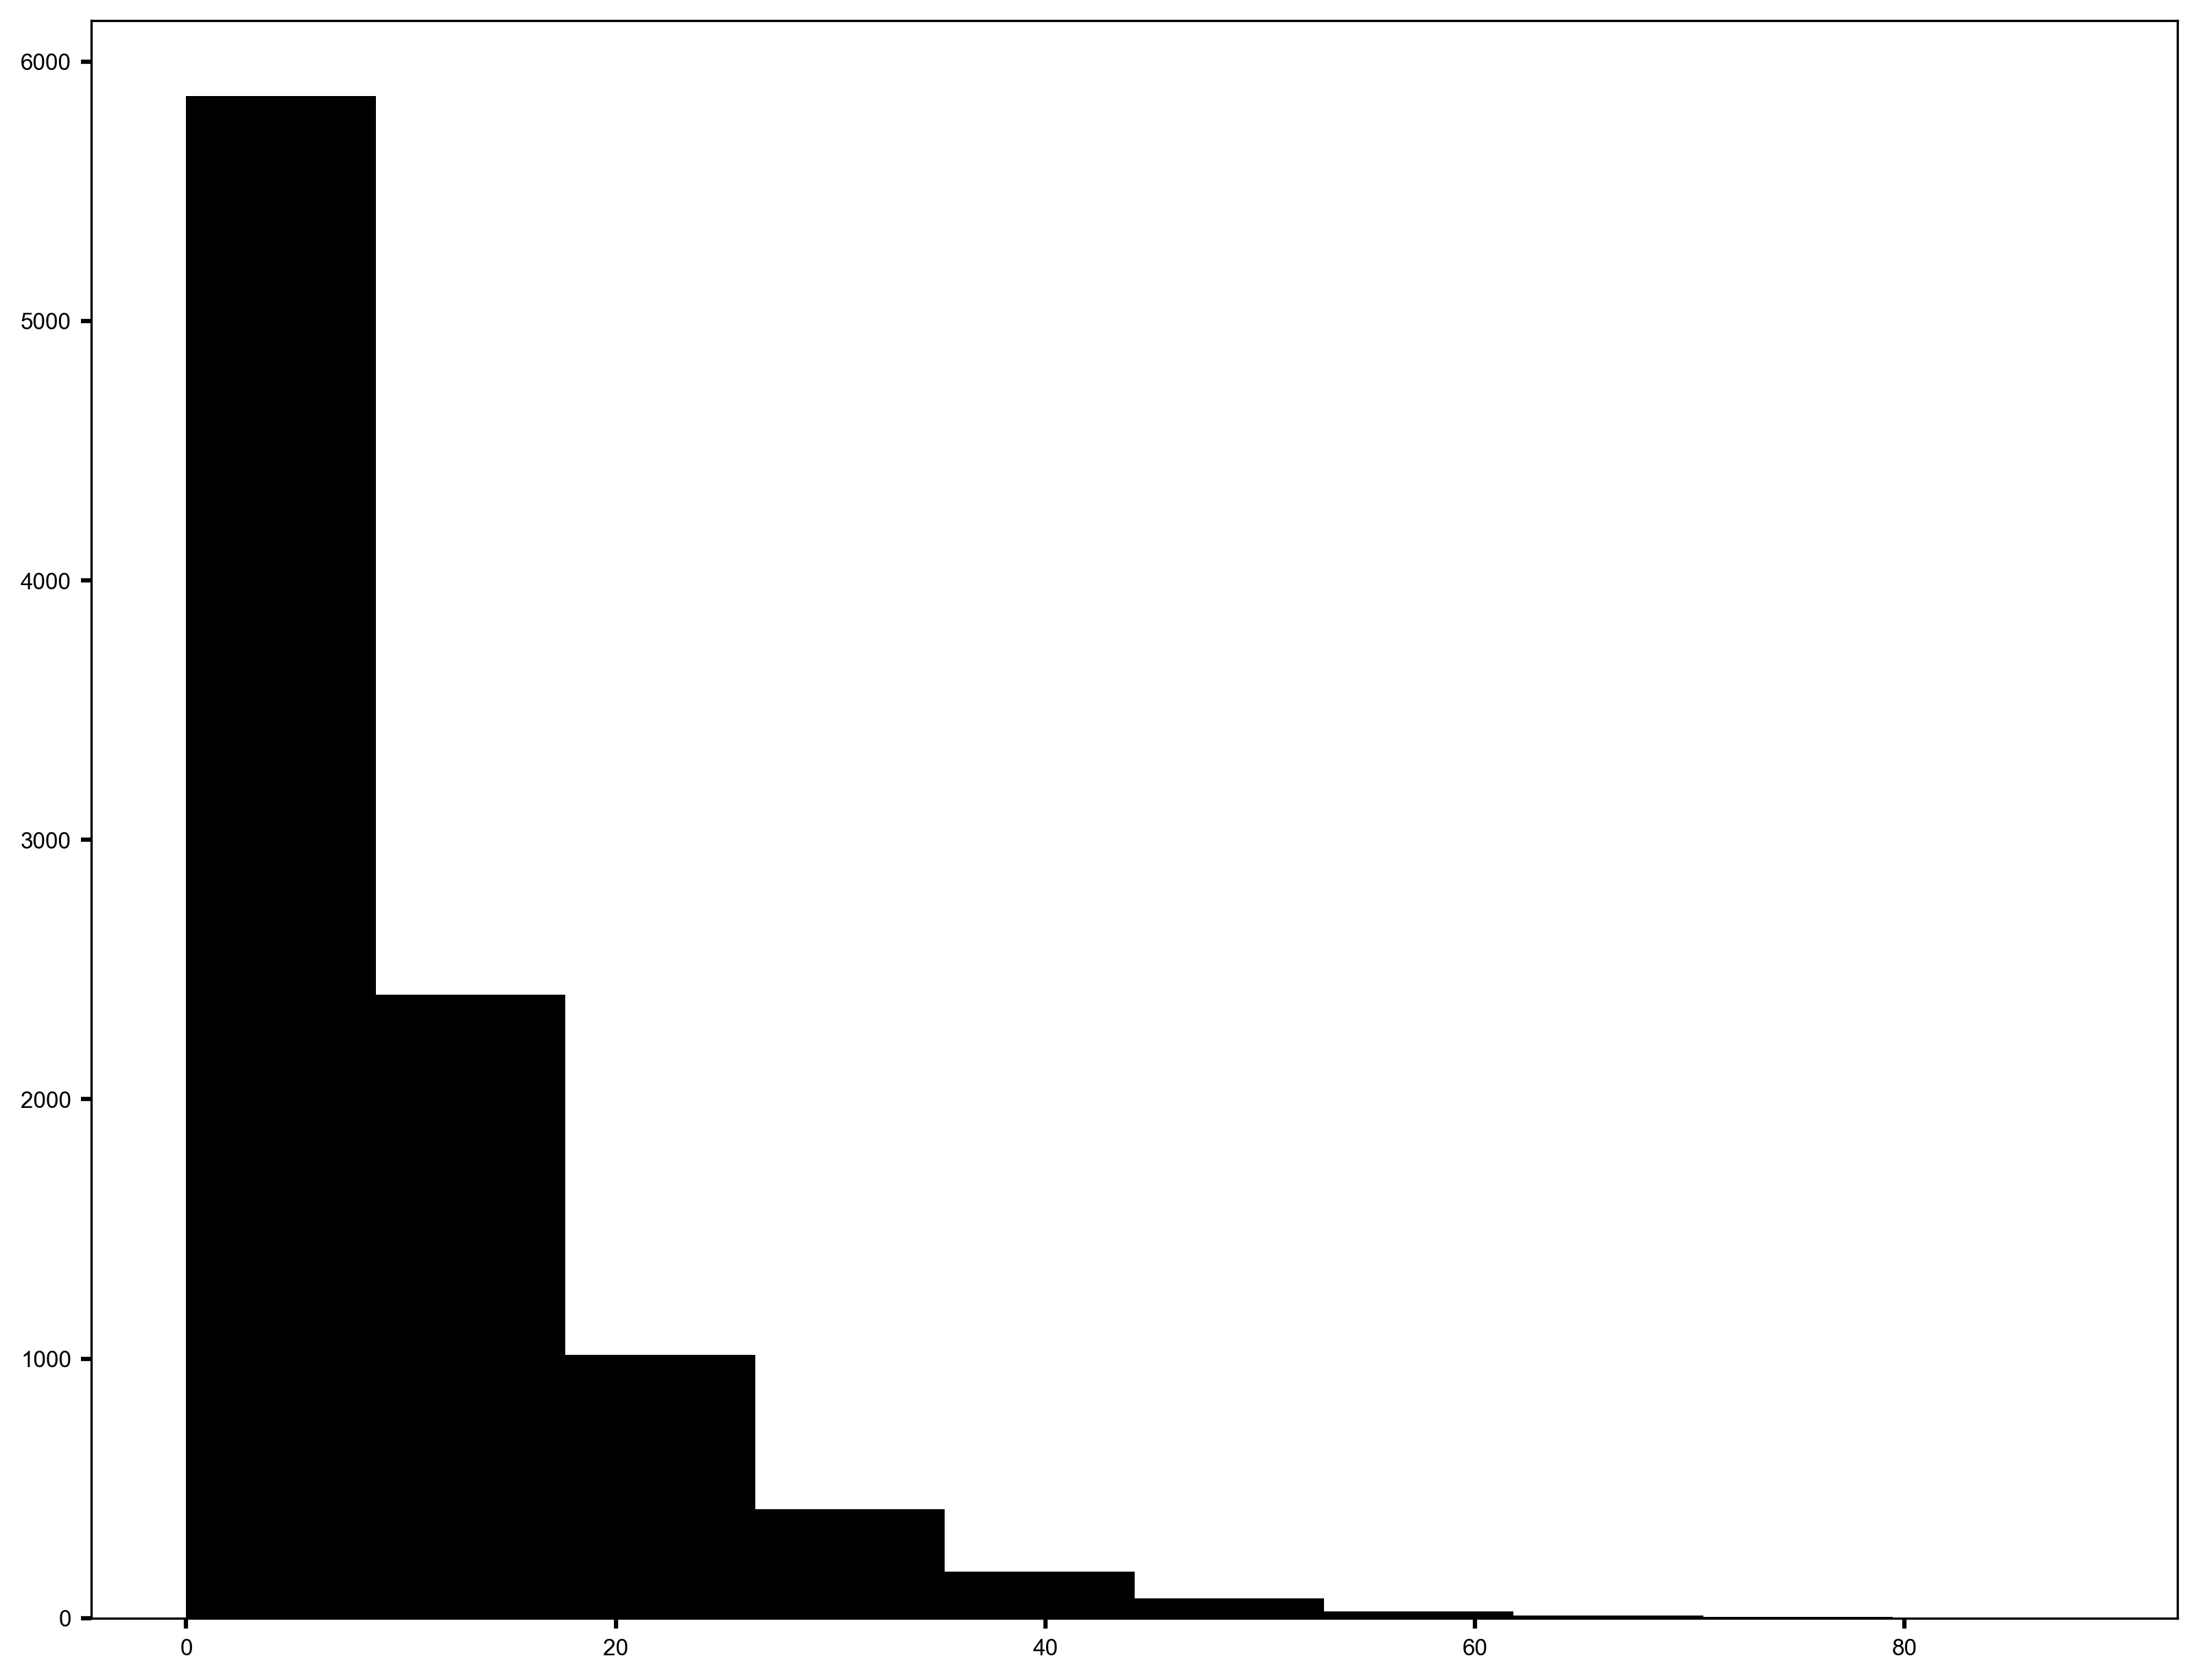

In [113]:
N=10000
t_wait = np.random.exponential(t_rxn, N)
plt.hist(t_wait, bins=10)

(array([3.000e+00, 8.000e+00, 1.700e+01, 4.900e+01, 7.700e+01, 1.440e+02,
        2.520e+02, 3.850e+02, 5.640e+02, 7.560e+02, 1.041e+03, 1.316e+03,
        1.657e+03, 1.999e+03, 2.408e+03, 2.703e+03, 2.931e+03, 3.371e+03,
        3.490e+03, 3.797e+03, 3.881e+03, 4.140e+03, 3.987e+03, 4.127e+03,
        4.162e+03, 4.192e+03, 4.087e+03, 3.839e+03, 3.666e+03, 3.564e+03,
        3.232e+03, 3.117e+03, 2.856e+03, 2.683e+03, 2.428e+03, 2.163e+03,
        2.086e+03, 1.841e+03, 1.636e+03, 1.480e+03, 1.312e+03, 1.139e+03,
        1.021e+03, 9.080e+02, 7.820e+02, 6.500e+02, 6.120e+02, 5.260e+02,
        4.480e+02, 3.770e+02, 3.180e+02, 3.020e+02, 2.510e+02, 1.890e+02,
        1.460e+02, 1.350e+02, 1.210e+02, 1.100e+02, 8.500e+01, 6.200e+01,
        7.800e+01, 4.000e+01, 4.500e+01, 3.700e+01, 3.900e+01, 2.100e+01,
        1.600e+01, 2.000e+01, 1.700e+01, 9.000e+00, 1.200e+01, 5.000e+00,
        6.000e+00, 1.000e+00, 3.000e+00, 1.000e+01, 3.000e+00, 1.000e+00,
        1.000e+00, 2.000e+00, 0.000e+0

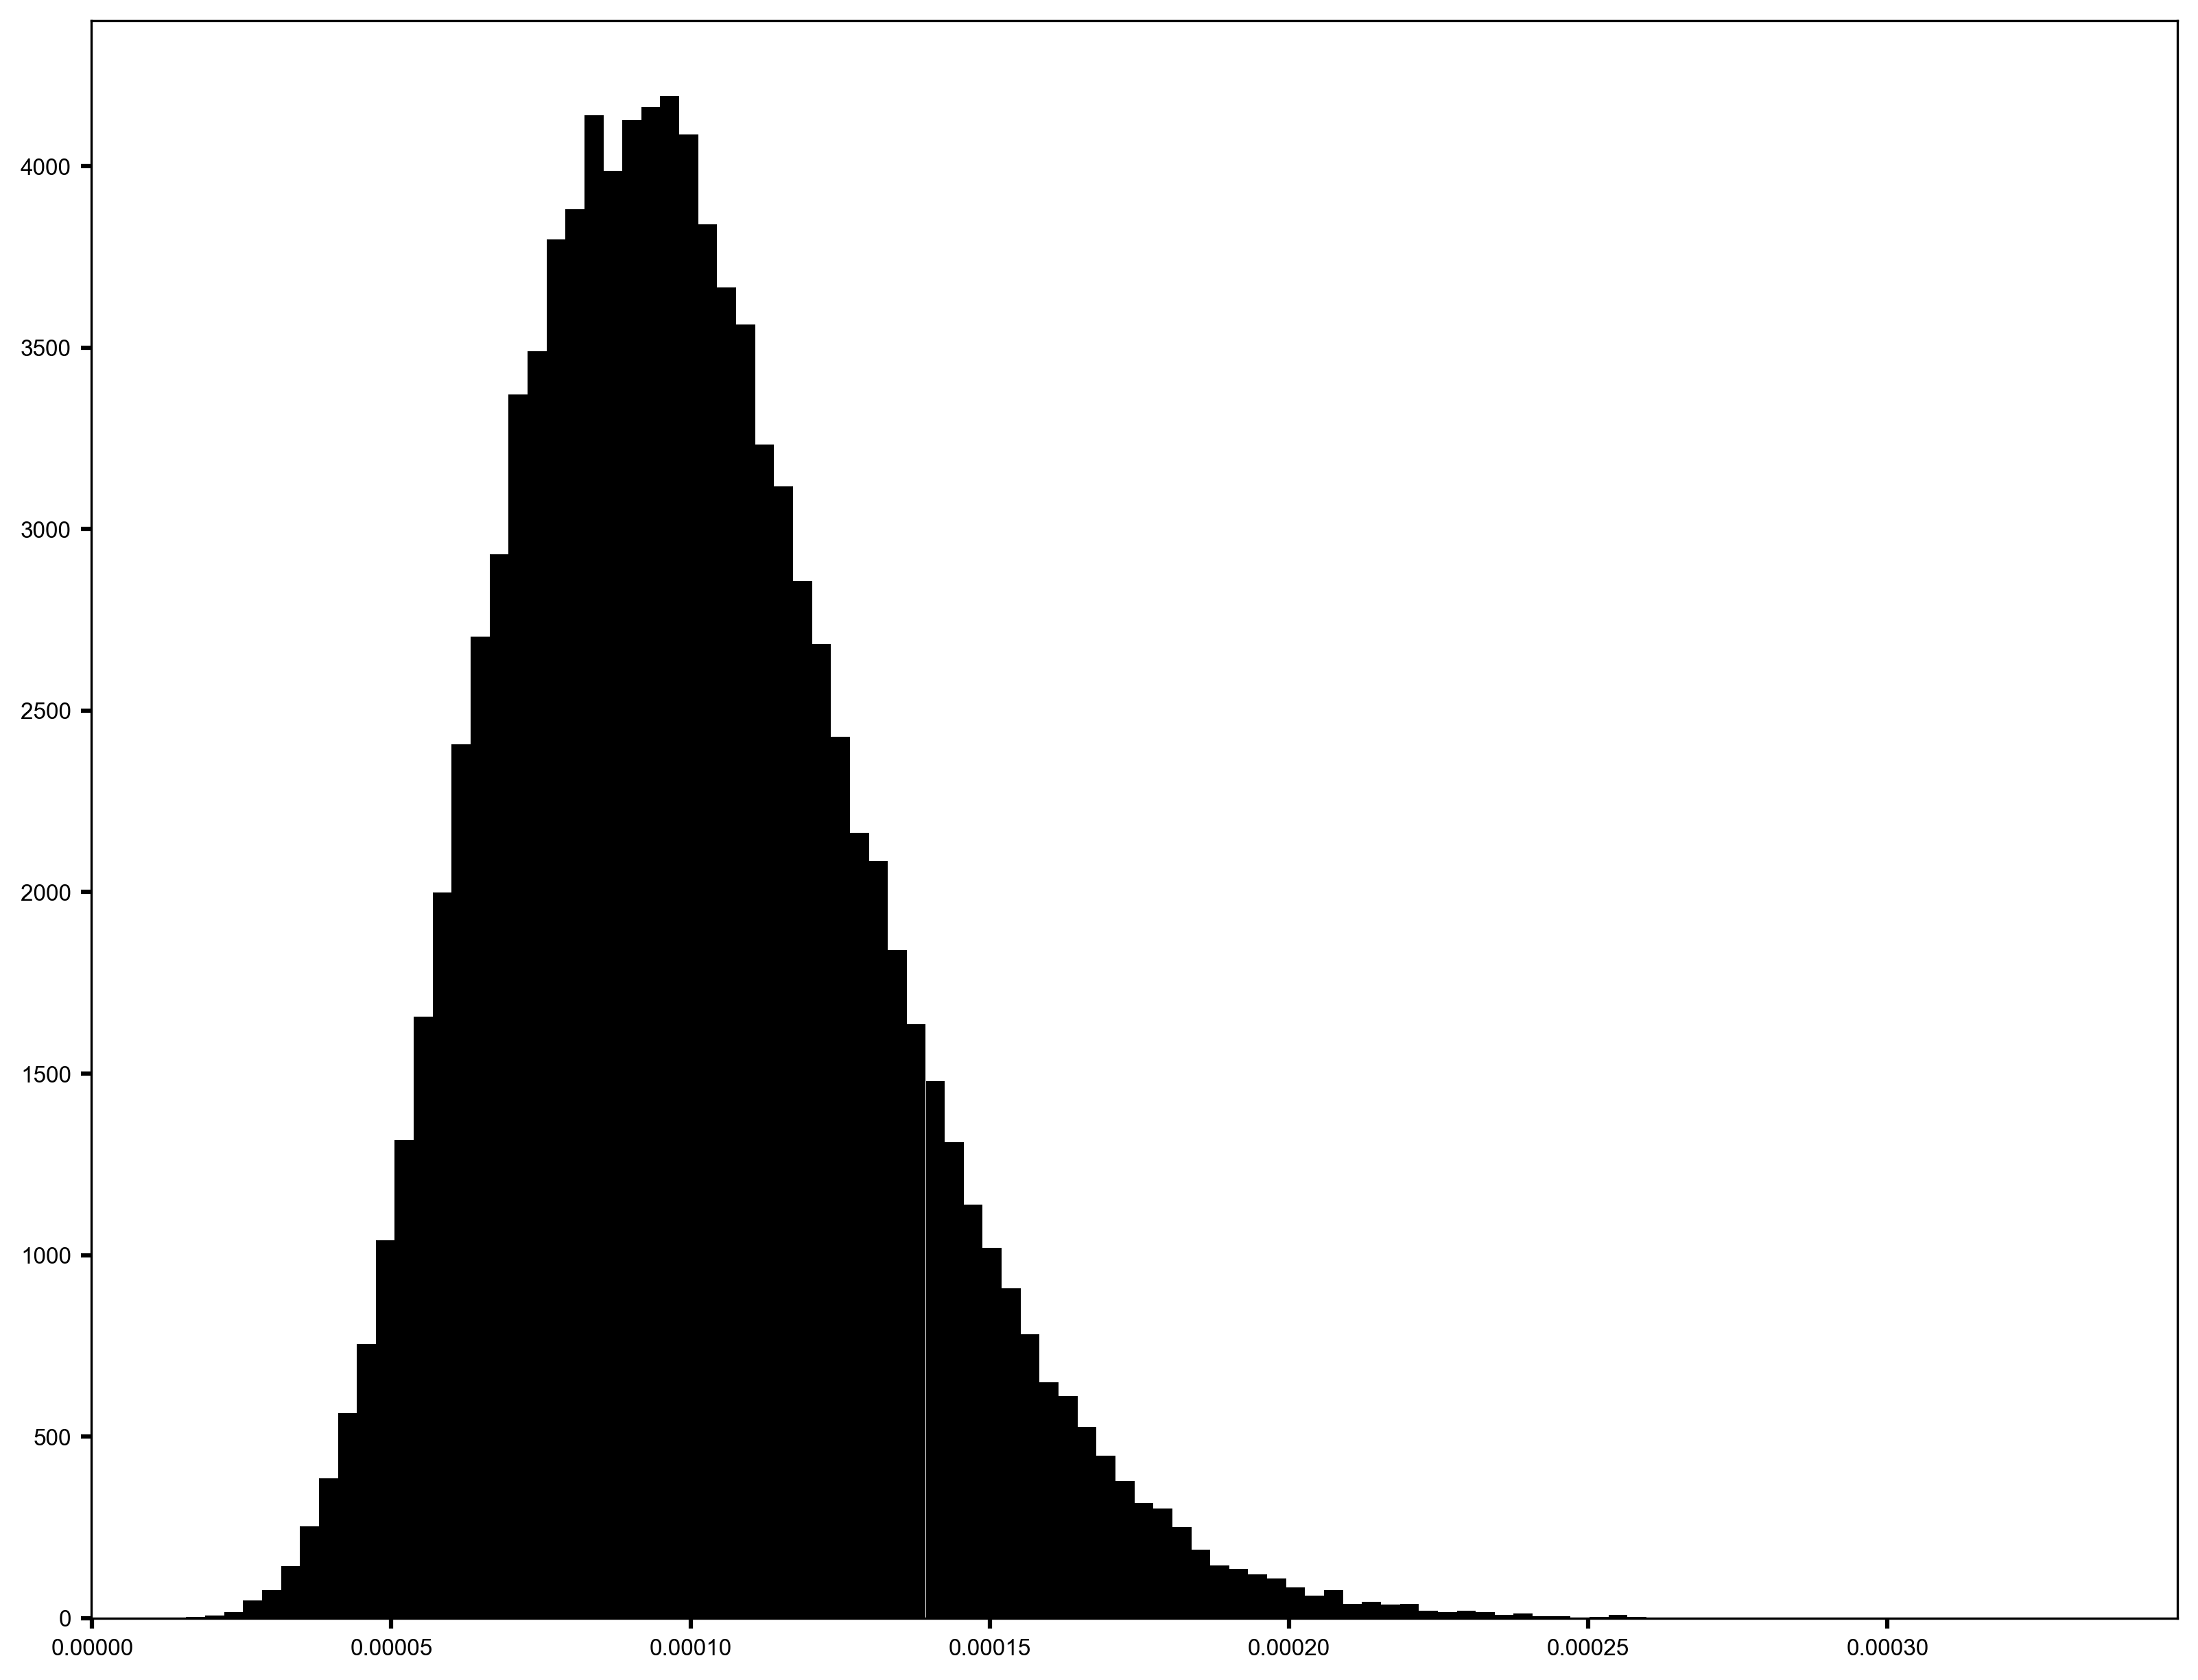

In [ ]:
import numpy.random
import numpy as np

alpha_24 = 100000
alpha_42 = 100000
t_24 = 1/alpha_24
t_42 = 1/alpha_42

N = 100000
n_nodes = 2
t_osc = np.random.exponential(t_24, N)

for i in range(n_nodes):
    t_osc += np.random.exponential(t_42, N)

plt.hist(t_osc, bins=100)

# 10/30/25: Generating spanning trees

In [76]:
import mpmath
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import lu_factor, lu_solve, null_space
import bokeh.layouts
import bokeh.models
import bokeh.plotting

from IPython.display import display
from jupyter_bokeh.widgets import BokehModel
from bokeh.io import output_notebook, export_svg, export_png
from bokeh.plotting import figure
from ipywidgets import interact

import math

from bokeh.io import output_file, show, export_svgs
from bokeh.layouts import row
from bokeh.models import Ellipse, GraphRenderer, StaticLayoutProvider, Circle
from bokeh.palettes import Spectral6, Reds3, brewer
from bokeh.plotting import figure
from IPython.display import display
from bokeh.models import (Arrow, Label, NormalHead, OpenHead,
                          Plot, Range1d, TeeHead, VeeHead)
import networkx as nx


In [112]:
G = nx.Graph()
G.add_nodes_from([2, 1, 0, 3, 4, 5])
G.add_edges_from([(0, 1), (1, 2), (0,2), (3,4), (4,5), (3,5), (0,3), (1,4), (2,5)])
# G = G.to_directed()

In [113]:
from bokeh.plotting import from_networkx
from bokeh.models import MultiLine, Plot, Range1d, Circle
from bokeh.palettes import Spectral4
from jupyter_bokeh.widgets import BokehModel

plot = figure(width=400, height=400,
            x_range=Range1d(-1.1,1.1), y_range=Range1d(-1.1,1.1), tools="hover", tooltips="index: @name",toolbar_location=None)

graph_renderer = from_networkx(G, nx.circular_layout, scale=1, center=(0,0))
graph_renderer.node_renderer.data_source.add([n for n in G], 'name')

graph_renderer.node_renderer.glyph = Circle(radius=0.1, fill_color=Spectral4[0])
graph_renderer.edge_renderer.glyph = MultiLine(line_color="#CCCCCC", line_alpha=0.8, line_width=5)
plot.renderers.append(graph_renderer)
display(BokehModel(plot))

interactive_python_plots = True
output_notebook()

BokehModel(render_bundle={'docs_json': {'91855131-e13d-4f3a-8e73-96fe1990195e': {'version': '3.7.2', 'title': …

Loading BokehJS ...

In [114]:
from itertools import product
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

def spanTrees(trs, Edg, all_span_trees, k):
    if k == 0:
        all_span_trees.extend(product(*trs))#Expand parallels edges using the Cartesian product
    
    for i in range(k):
        if Edg[k][i] == []: continue
        trs.append(Edg[k][i])
        Edg[i] = [Edg[i][j] + Edg[k][j] for j in range(i)]#Contraction 
        spanTrees(trs, Edg, all_span_trees, k-1)
        trs.pop()
        [Edg[i][j].pop() for j in range(i) for _ in range(len(Edg[k][j]))]#Deletion
#Helper function
def Spanning_Trees_Generator(g, hch = False):
    if not nx.is_connected(g):
        print("Only for connected graphs")
        return 0
    if nx.is_directed(g): nx.to_undirected(g)
    n = g.number_of_nodes()
    edgs = list(g.edges)
    Edg = [[[] for _ in range(n)] for _ in range(n)]
    mx = len(edgs)
    edgNum = dict() #dictionary designed to store labeled edges where the keys are integer labels for the edges, and the values are tuples representing the ordinary edge definitions (in, out)

    for ed in edgs:
        i, j = sorted(ed)
        Edg[j][i] = [mx]
        edgNum[mx] = ed
        mx -= 1
    all_span_trees = []
    spanTrees([], Edg, all_span_trees, n-1)
  
    if hch:  
        return all_span_trees #Generate only the labeled edges (Keys) 
    else:
        return [nx.Graph(edgNum[k] for k in element) for element in all_span_trees] #Generate spanning trees as NetworkX graphics objects

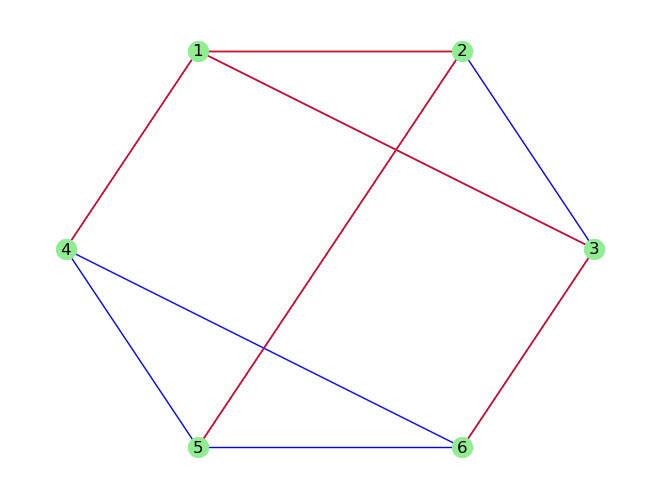

In [173]:
spanTreesGraph = Spanning_Trees_Generator(G)
spanTreesGraph[14] = np.nan
spanTreesGraph[17] = np.nan
spanTreesGraph[27] = np.nan
spanTreesGraph[30] = np.nan
spanTreesGraph[33] = np.nan
spanTreesGraph[58] = np.nan
spanTreesGraph[61] = np.nan
spanTreesGraph[70] = np.nan
spanTreesGraph[73] = np.nan
spanTreesGraph = [g for g in spanTreesGraph if type(g) != float]
pos = nx.circular_layout(G)
nx.draw(G, pos, with_labels=False, node_color='lightblue', node_size=200, edge_color='b')
nx.draw(spanTreesGraph[0], pos, labels = {n: n+1 for n in G}, node_color='lightgreen', node_size=200, edge_color='r')
plt.show()

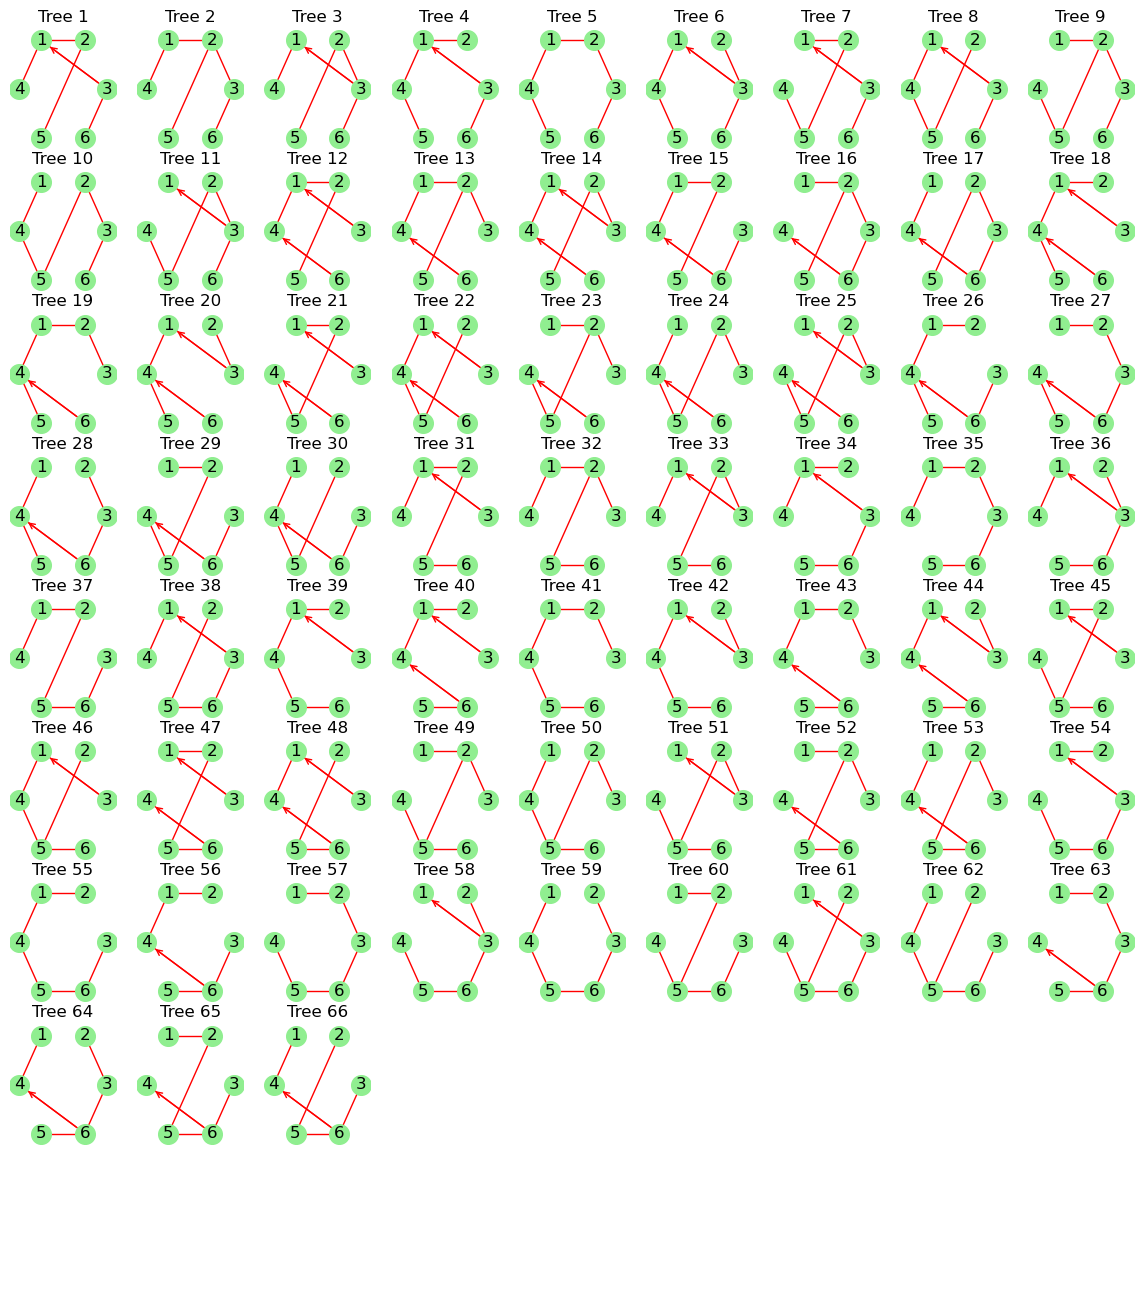

In [174]:
fig, axs = plt.subplots(9, 9, figsize=(1.8125 * 8, 1.8125 * 9))
pos = nx.circular_layout(G)

for i, g in enumerate(spanTreesGraph):
    x_ax = i // 9
    y_ax = i % 9
    if (0,2) in g.edges or (2,0) in g.edges :
        axs[x_ax][y_ax].annotate('', xy=np.array(pos[0]) + 0.1 * (np.array(pos[2]) - np.array(pos[0])), xytext=np.array(pos[2]) - 0.1 * (np.array(pos[2]) - np.array(pos[0])), \
                                 arrowprops=dict(arrowstyle='->', color='red'))
    if (3,5) in g.edges or (5,3) in g.edges:
        axs[x_ax][y_ax].annotate('', xy=np.array(pos[3]) + 0.1 * (np.array(pos[5]) - np.array(pos[3])), xytext=np.array(pos[5]) - 0.1 * (np.array(pos[5]) - np.array(pos[3])), \
                                 arrowprops=dict(arrowstyle='->', color='red'))
    axs[x_ax][y_ax].set_title(f"Tree {i+1}")
    nx.draw(g, pos, labels = {n: n+1 for n in G}, node_color='lightgreen', node_size=200, edge_color='r', ax=axs[x_ax][y_ax])

for i in range(9):
    for j in range(9):
        axs[i][j].axis('off')
plt.show()


In [175]:
# calculate all rooted trees weights for  given spanning tree

def root_tree_weights(spanning_tree, weights, nodes=None, prefactor=1):
    if nodes is None:
        nodes = [n for n in spanning_tree]

    if (3,5) in spanning_tree.edges or (5,3) in spanning_tree.edges:
        spanning_tree.remove_edges_from([(3,5), (5,3)])
        nodes = nx.node_connected_component(spanning_tree, 3)
        prefactor = root_tree_weights(spanning_tree, weights, nodes=[5], prefactor=prefactor) * weights.get((5, 3))

    if (0,2) in spanning_tree.edges or (2,0) in spanning_tree.edges:
        spanning_tree.remove_edges_from([(0,2), (2,0)])
        nodes = nx.node_connected_component(spanning_tree, 0)
        prefactor = root_tree_weights(spanning_tree, weights, nodes=[2], prefactor=prefactor) * weights.get((2, 0))
    
    total_weight = 0
    for root in nodes:
        # Perform BFS to get the tree structure rooted at 'root'
        BFS_list = []
        visited = set()
        queue = [root]
        while queue:
            current = queue.pop(0)
            visited.add(current)
            for neighbor in spanning_tree.neighbors(current):
                BFS_list.append((neighbor, current))  # Store as (child, parent)
                if neighbor not in visited and (current, neighbor) in spanning_tree.edges:
                    queue.append(neighbor)
        # Calculate the weight of the rooted tree
        tree_weight = np.prod([weights.get((u, v)) for u, v in BFS_list] + [1]) * prefactor
        # Store or process the tree weight as needed
        total_weight += tree_weight

    return total_weight

def map_graph_weights(alpha_32=1, alpha_21=1, alpha_65=1, alpha_54=1, alpha_14=1, alpha_41=1, dG_1=2, dG_2=2, gamma=10, epsilon_1=0, epsilon_2=0, k_bT=1):
    alpha_12 = alpha_21 * np.exp((dG_1 + epsilon_1) / k_bT)
    alpha_23 = alpha_32 * np.exp((dG_2 - epsilon_1)/ k_bT)

    alpha_54 = alpha_21
    alpha_65 = alpha_32
    alpha_45 = alpha_54 * np.exp((dG_1 + epsilon_2) / k_bT)
    alpha_56 = alpha_65 * np.exp((dG_2 - epsilon_2) / k_bT)



    alpha_25 = alpha_14
    alpha_52 = alpha_41
    alpha_36 = alpha_14
    alpha_63 = alpha_41
    d = {        
        (0, 1) : alpha_12,
        (1, 0) : alpha_21,
        (1, 2) : alpha_23,
        (2, 1) : alpha_32,
        (3, 4) : alpha_45,
        (4, 3) : alpha_54,
        (4, 5) : alpha_56,
        (5, 4) : alpha_65,
        (0, 3) : alpha_14,
        (3, 0) : alpha_41,
        (1, 4) : alpha_25,
        (4, 1) : alpha_52,
        (2, 5) : alpha_36,
        (5, 2) : alpha_63,
        (2, 0) : gamma,
        (5, 3) : gamma,
    }

    return d

# Gillespie algorithm with two states

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def gillespie_two_state(k_forward, k_backward, initial_state=0, max_time=10.0, seed=None):
    """
    Gillespie algorithm for a two-state stochastic process.
    
    Parameters:
    - k_forward: rate constant for transition 0 -> 1
    - k_backward: rate constant for transition 1 -> 0
    - initial_state: starting state (0 or 1)
    - max_time: simulation end time
    - seed: random seed for reproducibility
    
    Returns:
    - times: array of transition times
    - states: array of states at each transition
    """
    if seed is not None:
        np.random.seed(seed)
    
    times = [0.0]
    states = [initial_state]
    current_state = initial_state
    current_time = 0.0
    
    while current_time < max_time:
        # Determine propensity functions based on current state
        if current_state == 0:
            propensity_forward = k_forward
            propensity_backward = 0
        else:
            propensity_forward = 0
            propensity_backward = k_backward
        
        total_propensity = propensity_forward + propensity_backward
        
        # Sample time to next event (exponential distribution)
        tau = np.random.exponential(1.0 / total_propensity)
        current_time += tau
        
        if current_time >= max_time:
            break
        
        # Determine which transition occurs
        if propensity_forward > 0:
            current_state = 1
        else:
            current_state = 0
        
        times.append(current_time)
        states.append(current_state)
    
    return np.array(times), np.array(states)


def plot_trajectory(times, states, title="Two-State Gillespie Simulation"):
    """Plot the state trajectory over time."""
    plt.figure(figsize=(12, 5))
    
    # Plot trajectory
    plt.step(times, states, where='post', linewidth=2, color='blue')
    plt.xlabel('Time')
    plt.ylabel('State')
    plt.title(title)
    plt.ylim(-0.5, 1.5)
    plt.yticks([0, 1])
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()



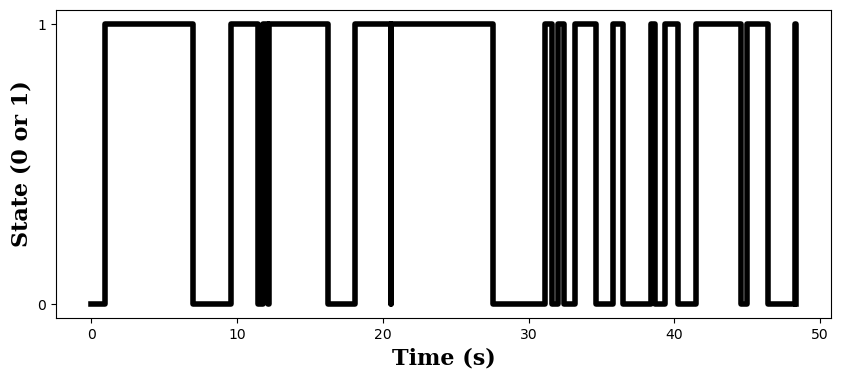

In [77]:
# Parameters
k_on = 0.5    # rate 0 -> 1
k_off = 0.5   # rate 1 -> 0

# Run simulation
times_stoch, states_stoch = gillespie_two_state(k_on, k_off, initial_state=0, max_time=50.0, seed=42)

fig, ax = plt.subplots(figsize=(10, 4))
ax.step(times_stoch, states_stoch, where='post', linewidth=4, color='black')
ax.set_xlabel('Time (s)', fontdict={'size': 16, 'weight': 'bold', 'family': 'serif'})
ax.set_ylabel('State (0 or 1)', fontdict={'size': 16, 'weight': 'bold', 'family': 'serif'})
# ax.set_title('Two-State Gillespie Simulation')
ax.set_yticks(np.arange(0, 1.1, 1))
ax.set_xticks(np.arange(0, 51, 10))


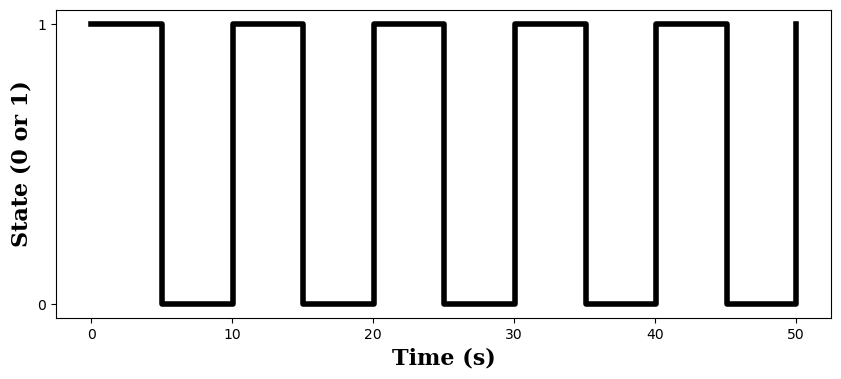

In [78]:
# deterministic
from scipy import signal
times_det = np.linspace(0, 50, 500)
states_det = 0.5 * signal.square(2 * np.pi /10 * times ) + 0.5
fig, ax = plt.subplots(figsize=(10, 4))
ax.step(times, states, where='post', linewidth=4, color='black')
ax.set_xlabel('Time (s)', fontdict={'size': 16, 'weight': 'bold', 'family': 'serif'})
ax.set_ylabel('State (0 or 1)', fontdict={'size': 16, 'weight': 'bold', 'family': 'serif'})
ax.set_yticks(np.arange(0, 1.1, 1))
ax.set_xticks(np.arange(0, 51, 10))
# ax.set_title('Two-State Gillespie Simul

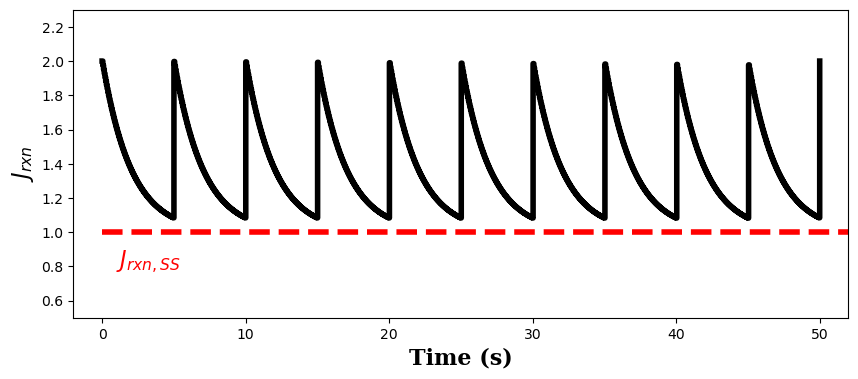

In [79]:
# you should probable just simulate this.
import numpy as np
import matplotlib.pyplot as plt

def square_wave_with_relaxation(t, period=1.0, amplitude=1.0, tau=0.1, steady_state_high=1.0, steady_state_low=0.0):
    """
    Generate a square wave where flat parts relax exponentially to steady-state values.
    
    Parameters:
    - t: time array
    - period: period of the square wave
    - amplitude: initial amplitude of transitions
    - tau: time constant for exponential relaxation
    - steady_state_high: target value for high state
    - steady_state_low: target value for low state
    """
    signal = np.zeros_like(t)
    half_period = period / 2
    
    for i, time in enumerate(t):
        # Determine which half of the period we're in
        t_mod = time % period
        
        if t_mod < half_period:
            # High state - relax from amplitude towards steady_state_high
            t_since_transition = t_mod
            signal[i] = steady_state_high + (amplitude - steady_state_high) * np.exp(-t_since_transition / tau)
        else:
            # Low state - relax from -amplitude towards steady_state_low
            t_since_transition = t_mod - half_period
            signal[i] = steady_state_low + (amplitude - steady_state_low) * np.exp(-t_since_transition / tau)
    
    return signal

# Example usage
t_det = np.linspace(0, 50, 1000)
signal_det = square_wave_with_relaxation(t, period=10, amplitude=2, tau=2, 
                                      steady_state_high=1, steady_state_low=1)

plt.figure(figsize=(10, 4))
plt.step(t_det, signal_det, where='post', linewidth=4, color='black')
plt.plot(np.linspace(0, 55, 1000), 1 + 0*np.linspace(0, 50, 1000), 'r--', linewidth=4)
plt.xlabel('Time (s)', fontdict={'size': 16, 'weight': 'bold', 'family': 'serif'})
plt.ylabel('$J_{rxn}$', fontdict={'size': 16, 'weight': 'bold', 'family': 'serif'})
plt.annotate('$J_{rxn, SS}$', xy=(2, 0.8), xytext=(1, 0.8), color='red', fontsize=16)
# plt.yticks(np.arange(0, 1.1, 1))
plt.xticks(np.arange(0, 51, 10))
plt.xlim(-2, 52)
plt.ylim(0.5, 2.3)
plt.show()

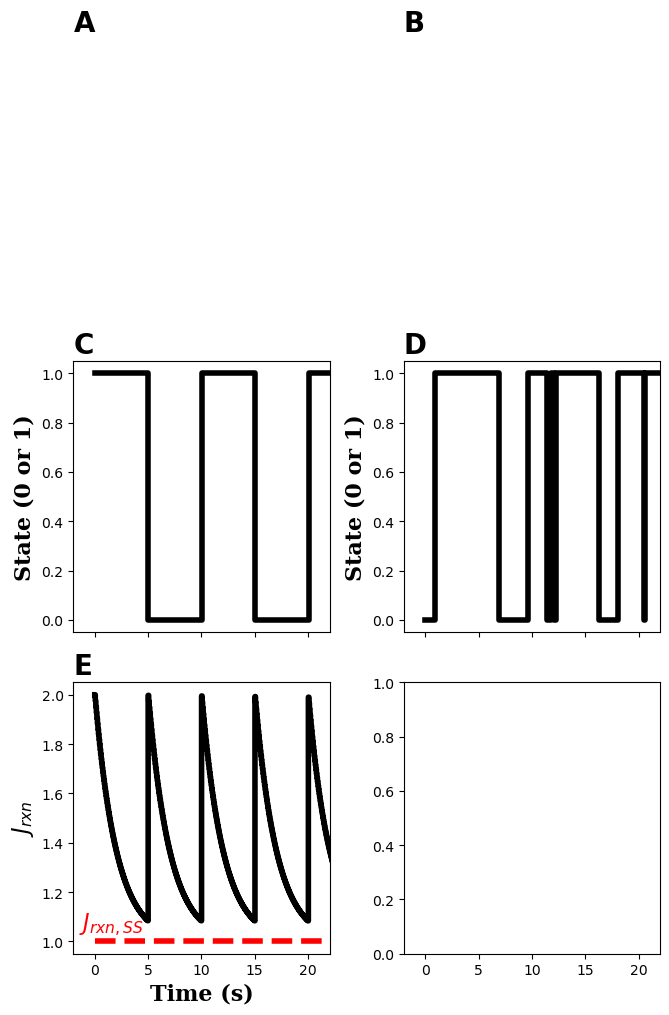

In [98]:
fig, axs = plt.subplots(3, 2, figsize=(6.8, 10.26), sharex=True)
ax = axs[0,0]
ax.set_title('A', fontdict={'size': 20,'weight': 'bold'}, loc='left')
ax.set_axis_off()
ax = axs[0,1]
ax.set_title('B', fontdict={'size': 20,'weight': 'bold'}, loc='left')
ax.set_axis_off()
ax = axs[1,1]
ax.step(times_stoch, states_stoch, where='post', linewidth=4, color='black')
ax.set_ylabel('State (0 or 1)', fontdict={'size': 16,'weight': 'bold', 'family': 'serif'})
ax.set_title('D', fontdict={'size': 20,'weight': 'bold'}, loc='left')

ax = axs[1,0]
ax.step(times_det, states_det, where='post', linewidth=4, color='black')
ax.set_ylabel('State (0 or 1)', fontdict={'size': 16,'weight': 'bold', 'family': 'serif'})
ax.set_title('C', fontdict={'size': 20,'weight': 'bold'}, loc='left')

ax = axs[2,0]
ax.step(t_det, signal_det, where='post', linewidth=4, color='black')
ax.plot(np.linspace(0, 55, 1000), 1 + 0*np.linspace(0, 50, 1000), 'r--', linewidth=4)   
ax.set_xlabel('Time (s)', fontdict={'size': 16,'weight': 'bold', 'family': 'serif'})
ax.set_ylabel('$J_{rxn}$', fontdict={'size': 16,'weight':'bold', 'family': 'serif'})
ax.annotate('$J_{rxn, SS}$', xy=(1, 1.05), xytext=(-1.5, 1.05), color='red', fontsize=16)
ax.set_xlim(-2, 22)
ax.set_title('E', fontdict={'size': 20,'weight': 'bold'}, loc='left')

plt.tight_layout()
plt.show()